In [1]:
# === Ô GHI LOG  ===
import logging, sys, datetime, warnings
from pathlib import Path
TEN_NOTEBOOK = "01_E0.4_so_dac_trung_toi_uu_Han"
NGUOI_CHAY   = "Han"

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())  # thư mục gốc repo
thu_muc_log = ROOT / "logs" / "eda_log"
thu_muc_log.mkdir(parents=True, exist_ok=True)
file_log = thu_muc_log / f"{datetime.datetime.now():%Y-%m-%d_%H%M}_{TEN_NOTEBOOK}.log"
tep_log = open(file_log, "a", encoding="utf-8", buffering=1)

if hasattr(sys.stdout, "echo"):                  # chạy trong Jupyter / VS Code: nhờ kernel chép thêm ra file, không thay sys.stdout
    sys.stdout.echo = tep_log
    sys.stderr.echo = tep_log
else:                                            # chạy bằng python thường
    class GhiCaHai:
        def __init__(self, man_hinh, tep): self.man_hinh, self.tep = man_hinh, tep
        def write(self, s): self.man_hinh.write(s); self.tep.write(s); return len(s)
        def flush(self): self.man_hinh.flush(); self.tep.flush()
        def __getattr__(self, ten): return getattr(self.man_hinh, ten)
    sys.stdout = GhiCaHai(sys.__stdout__, tep_log)

logging.basicConfig(stream=sys.stdout, level=logging.INFO, force=True,
                    format="%(asctime)s | %(levelname)s | %(message)s", datefmt="%Y-%m-%d %H:%M:%S")
logging.captureWarnings(True)
log = logging.getLogger(TEN_NOTEBOOK)
log.info(f"Bắt đầu chạy {TEN_NOTEBOOK} – người chạy: {NGUOI_CHAY} – file log: {file_log}")

2026-11-13 18:36:59 | INFO | Bắt đầu chạy 01_E0.4_so_dac_trung_toi_uu_Han – người chạy: Han – file log: /Users/caongochan/Documents/Challenge_1_House_Prices/logs/2026-11-13_1836_01_E0.4_so_dac_trung_toi_uu_Han.log


2026-11-13 18:37:01 | INFO | ROOT: /Users/caongochan/Documents/Challenge_1_House_Prices
train: (1460, 81) | test: (1459, 80)
2026-11-13 18:37:01 | INFO | 79 đặc trưng (36 số, 43 phân loại)
2026-11-13 18:37:01 | INFO | Đã đọc xếp hạng E0.2: 79 đặc trưng, top 3 = ['OverallQual', 'Neighborhood', 'GrLivArea']
2026-11-13 18:37:01 | INFO | Căn diện tích > 4000 nhưng giá < 300k (Id): [524, 1299]
Sweet spot: 19 đặc trưng, R² = 0.918 (cao nhất 0.923 ở k = 30)
Thứ tự SFS chọn: OverallQual, GrLivArea, Neighborhood, BsmtFinSF1, OverallCond, YearBuilt, TotalBsmtSF, GarageCars, BldgType, MSZoning, SaleCondition, LotArea, CentralAir, KitchenQual, Functional, BsmtExposure, Condition1, ScreenPorch, Fireplaces
2026-11-13 18:37:10 | INFO | Tóm tắt E0.4:
E0.4 (C1): sweet spot 19 đặc trưng, R² CV = 0.918 (cao nhất 0.923); top-19 theo E0.2 chỉ đạt 0.882.
  SFS chọn: OverallQual, GrLivArea, Neighborhood, BsmtFinSF1, OverallCond, YearBuilt, TotalBsmtSF, GarageCars, BldgType, MSZoning, SaleCondition, LotArea, 

# E0.4 – Bao nhiêu đặc trưng là đủ? (C1 – House Prices)

| | |
|---|---|
| **Tác giả** | Cao Ngọc Hân – Nhóm 11 |
| **Ngày tạo** | 13/11/2026 – tách từ `01_eda_Han.ipynb` (bản 08/11/2026, nay ở `notebooks/eda/phien_ban_cu/`) |
| **Thí nghiệm** | E0.4 – Bao nhiêu đặc trưng là đủ? |
| **Câu hỏi nghiên cứu** | RQ0: Những đặc trưng nào quyết định giá nhà, và cần bao nhiêu đặc trưng là đủ? |
| **Đọc vào** | `data/raw/train.csv`, `figures/eda/c1_E0.2_xep_hang_dac_trung.csv` (từ E0.2) |
| **Ghi ra** | `figures/eda/c1_E0.4_duong_cong_so_dac_trung.csv`, hình sweet spot, `c1_E0.4_tom_tat.txt` |

**Lịch sử sửa**

| Ngày | Người | Nội dung |
|---|---|---|
| 07–08/11/2026 | Hân | Viết trong `01_eda_Han.ipynb` (E0.1–E0.4 chung một notebook) |
| 13/11/2026 | Hân | Tách thành notebook riêng; thêm ô ghi log ra `logs/` |

**Cách chạy:** chạy các notebook EDA theo thứ tự E0.1 → E0.2 → E0.3 → E0.4 (Run All). File log nằm ở `logs/eda_log/`.

In [2]:
import os, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.feature_selection import mutual_info_regression
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid", font_scale=1.0)

SEED = 42
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())  # notebook nằm ở notebooks/eda/
DATA = ROOT / "data" / "raw"
FIG = ROOT / "figures" / "eda"
FIG.mkdir(parents=True, exist_ok=True)

# W&B: USE_WANDB là công tắc chung; LOG chọn thí nghiệm nào được log ở lần chạy này.
# Thí nghiệm đã log rồi thì để False để không tạo run trùng.
# Các run W&B của E0.1–E0.4 đã log ngày 07–08/11 (xem evidence/c1_wandb_Han_10-11.png).
# Để USE_WANDB = False khi chạy lại để không tạo run trùng; bật True nếu cần log run mới.
USE_WANDB = False
LOG = {"E0.4": True}
WANDB_ENTITY = "sgu-mayhoc-nhom11"
WANDB_PROJECT = "challenge-1-house-prices"
log.info(f"ROOT: {ROOT}")

In [3]:
train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")
TARGET = "SalePrice"
print("train:", train.shape, "| test:", test.shape)
train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [4]:
# Chuẩn bị chung (lấy lại từ E0.1): tách đặc trưng, kiểu cột, biến mục tiêu
X = train.drop(columns=["Id", TARGET])
num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
y = train[TARGET]
y_log = np.log1p(y)
log.info(f"{X.shape[1]} đặc trưng ({len(num_cols)} số, {len(cat_cols)} phân loại)")

In [5]:
# Chuẩn bị: điền thiếu đơn giản chỉ để phân tích (không phải pipeline mô hình)
Xa = X.copy()
for c in num_cols:
    Xa[c] = Xa[c].fillna(Xa[c].median())
for c in cat_cols:
    Xa[c] = Xa[c].fillna("Missing")
X_codes = Xa.copy()
for c in cat_cols:
    X_codes[c] = X_codes[c].astype("category").cat.codes

In [6]:
# Đọc xếp hạng đặc trưng do notebook E0.2 tạo ra (chạy 01_E0.2 trước)
scores = pd.read_csv(FIG / "c1_E0.2_xep_hang_dac_trung.csv", index_col=0)
log.info(f"Đã đọc xếp hạng E0.2: {len(scores)} đặc trưng, top 3 = {list(scores.index[:3])}")

In [7]:
# Hai căn diện tích lớn giá thấp (cùng điều kiện như E0.3)
big_cheap = train[(train["GrLivArea"] > 4000) & (train["SalePrice"] < 300000)]["Id"].tolist()
log.info(f"Căn diện tích > 4000 nhưng giá < 300k (Id): {big_cheap}")

## E0.4 – Bao nhiêu đặc trưng là đủ?

Chọn đặc trưng tuần tự tiến (forward SFS): bắt đầu từ tập rỗng, mỗi bước thêm đặc trưng làm R² 5-fold CV tăng nhiều nhất. Mô hình đơn giản: Ridge (α = 1) trên log(SalePrice); đặc trưng số được chuẩn hóa, đặc trưng phân loại được one-hot (mỗi đặc trưng phân loại tính là **một** đặc trưng). Bỏ 2 ngoại lai diện tích lớn giá thấp tìm được ở E0.3.

So sánh thêm đường "lấy top-k theo xếp hạng E0.2" để xem xếp hạng đơn biến có đủ tốt không. **Sweet spot** là số đặc trưng nhỏ nhất đạt R² cách mức cao nhất không quá 0.005.

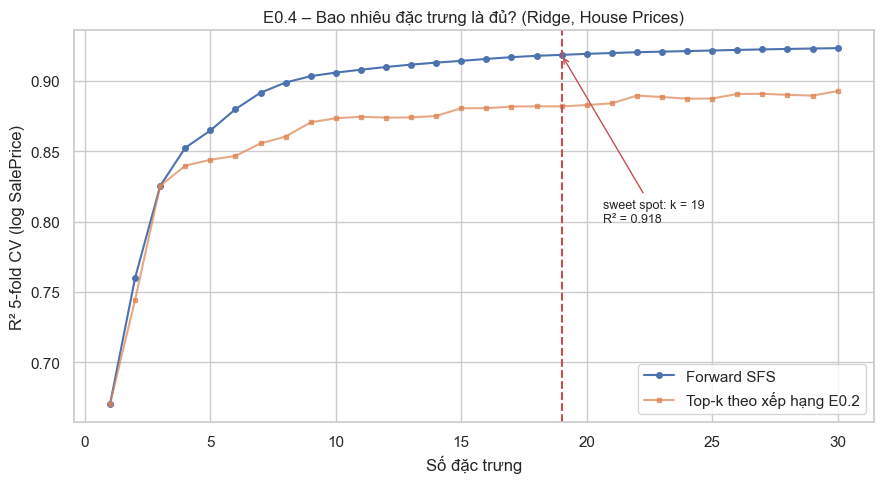

In [8]:
from sklearn.linear_model import Ridge
K_MAX = 30
keep = ~train["Id"].isin(big_cheap)
Xs, ys = Xa[keep].reset_index(drop=True), y_log[keep].reset_index(drop=True)

# Mỗi đặc trưng gốc → một khối cột (số: chuẩn hóa; phân loại: one-hot)
blocks = {}
for c in X.columns:
    if c in num_cols:
        v = Xs[c].astype(float)
        blocks[c] = ((v - v.mean()) / (v.std() if v.std() > 0 else 1)).to_numpy()[:, None]
    else:
        blocks[c] = pd.get_dummies(Xs[c], drop_first=True).to_numpy(dtype=float)
kf4 = KFold(n_splits=5, shuffle=True, random_state=SEED)
def cv_r2(feats):
    M = np.hstack([blocks[f] for f in feats])
    return cross_val_score(Ridge(alpha=1.0), M, ys, cv=kf4, scoring="r2").mean()

selected, sfs_curve = [], []
remaining = list(X.columns)
for k in range(1, K_MAX + 1):
    best = max(remaining, key=lambda f: cv_r2(selected + [f]))
    selected.append(best); remaining.remove(best)
    sfs_curve.append(cv_r2(selected))
rank_order = list(scores.index)
rank_curve = [cv_r2(rank_order[:k]) for k in range(1, K_MAX + 1)]

curve = pd.DataFrame({"k": range(1, K_MAX + 1), "dac_trung_them_vao": selected,
                      "R2_SFS": sfs_curve, "R2_top_k_E0.2": rank_curve})
best_r2 = curve["R2_SFS"].max()
sweet_k = int(curve.loc[curve["R2_SFS"] >= best_r2 - 0.005, "k"].min())
curve.to_csv(FIG / "c1_E0.4_duong_cong_so_dac_trung.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(curve["k"], curve["R2_SFS"], marker="o", ms=4, label="Forward SFS")
ax.plot(curve["k"], curve["R2_top_k_E0.2"], marker="s", ms=3, alpha=0.7, label="Top-k theo xếp hạng E0.2")
ax.axvline(sweet_k, ls="--", color="#C44E52")
ax.annotate(f"sweet spot: k = {sweet_k}\nR² = {curve.at[sweet_k-1, 'R2_SFS']:.3f}",
            (sweet_k, curve.at[sweet_k-1, "R2_SFS"]), textcoords="offset points", xytext=(30, -120), fontsize=9,
            arrowprops=dict(arrowstyle="->", color="#C44E52"))
ax.set_xlabel("Số đặc trưng"); ax.set_ylabel("R² 5-fold CV (log SalePrice)")
ax.set_title("E0.4 – Bao nhiêu đặc trưng là đủ? (Ridge, House Prices)")
ax.legend(); plt.tight_layout(); plt.savefig(FIG / "c1_E0.4_sweet_spot.png", dpi=150); plt.show()
print(f"Sweet spot: {sweet_k} đặc trưng, R² = {curve.at[sweet_k-1, 'R2_SFS']:.3f} (cao nhất {best_r2:.3f} ở k = {int(curve.loc[curve['R2_SFS'].idxmax(), 'k'])})")
print("Thứ tự SFS chọn:", ", ".join(selected[:sweet_k]))

## Tóm tắt E0.4

In [9]:
summary = f"""E0.4 (C1): sweet spot {sweet_k} đặc trưng, R² CV = {curve.at[sweet_k-1, 'R2_SFS']:.3f} (cao nhất {best_r2:.3f}); top-{sweet_k} theo E0.2 chỉ đạt {curve.at[sweet_k-1, 'R2_top_k_E0.2']:.3f}.
  SFS chọn: {', '.join(selected[:sweet_k])}."""
log.info("Tóm tắt " + "E0.4" + ":\n" + summary)
(FIG / "c1_E0.4_tom_tat.txt").write_text(summary, encoding="utf-8")

342

## Log lên W&B (minh chứng)

In [10]:
if USE_WANDB:
    import wandb
    def log_run(exp, name, metrics, tables, images, config=None):
        if not LOG.get(exp):
            print(f"Bỏ qua {exp} (LOG = False)"); return
        run = wandb.init(entity=WANDB_ENTITY, project=WANDB_PROJECT, name=name,
                         tags=[exp, "Han", "EDA"], config={"seed": SEED, **(config or {})})
        run.log({**metrics,
                 **{k: wandb.Table(dataframe=v) for k, v in tables.items()},
                 **{f.removesuffix(".png"): wandb.Image(str(FIG / f)) for f in images}})
        run.finish()

    log_run("E0.4", "c1-E0.4-Han-so-dac-trung-toi-uu",
            {"sweet_spot_k": sweet_k, "r2_sweet_spot": float(curve.at[sweet_k-1, "R2_SFS"]), "r2_best": float(best_r2)},
            {"duong_cong": curve.round(4)},
            ["c1_E0.4_sweet_spot.png"],
            {"model": "Ridge(alpha=1)", "k_max": K_MAX, "cv_folds": 5, "dropped_outlier_ids": big_cheap})


## Nhật ký

- 08/11/2026 – Viết thí nghiệm số đặc trưng tối ưu (E0.4) lần đầu trong notebook `01_eda_Han.ipynb`. Commit `5f6c769`.
- 13/11/2026 – Tách E0.4 ra thành notebook riêng `01_E0.4_so_dac_trung_toi_uu_Han.ipynb`, thêm ô ghi log, đọc bảng xếp hạng từ E0.2. Chạy lại, số khớp bản 08/11. Commit `95e17ba`.